# CD-ADAPT-VQE on random graphs $n=6$

Analyzes the results of **CD-ADAPT-VQE** on an ensemble of 300 random graphs with $n=6$, comparing the operator pool $\ell=1$ against $\ell=2$, with and without a common iteration budget.

The base data was generated by running `cluster/main.py` (graphs in `datos/grafos_n6.txt`, $M=300$) for $\ell=1$ and $\ell=2$, and ended up in `resultados/csv/resultados_resumen_n6_l{1,2}_1_300.csv` and their analogous complete JSON files.

The "common budget" section truncates those complete traces to the minimum number of iterations between $\ell=1$ and $\ell=2$ per graph, in order to compare both pools under the same number of operators added to the ansatz.

## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("seaborn-whitegrid")

mpl.rcParams.update({
    "figure.dpi"       : 120,
    "figure.facecolor" : "white",
    "axes.facecolor"   : "white",
    "axes.spines.top"  : False,
    "axes.spines.right": False,
    "axes.grid"        : True,
    "grid.color"       : "#DDDDDD",
    "grid.linewidth"   : 0.6,
    "grid.alpha"       : 1.0,
    "font.family"      : "serif",
    "font.size"        : 11,
    "axes.labelsize"   : 11,
    "axes.titlesize"   : 12,
    "axes.titleweight" : "bold",
    "legend.fontsize"  : 10,
    "legend.framealpha": 0.9,
    "legend.edgecolor" : "#BBBBBB",
    "xtick.labelsize"  : 10,
    "ytick.labelsize"  : 10,
    "lines.linewidth"  : 2.0,
    "patch.linewidth"  : 0.4,
    "savefig.dpi"      : 150,
    "savefig.bbox"     : "tight",
    "savefig.facecolor": "white",
})

# Colorblind-safe palette (Wong 2011)
C1 = "#0072B2"   # blue      – l = 1
C2 = "#D55E00"   # vermilion – l = 2

import sys
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from functions.utilidades import (
    compute_error_stats,
    get_num_ops,
    truncate_trace_like_normal,
    truncate_ansatz_list,
    truncate_result_to_budget,
    save_json,
    save_csv,
)

## Analysis: free convergence

### 0. Data loading

In [2]:
# Load both files
df1 = pd.read_csv("results//csv//resultados_resumen_n6_l1_1_300.csv")
df2 = pd.read_csv("results//csv//resultados_resumen_n6_l2_1_300.csv")

# Check
print(df1.shape)  
print(df2.shape) 


(300, 9)
(300, 9)


> **What this case means:** each algorithm runs freely until the gradient norm falls below $\varepsilon = 10^{-2}$ or 50 iterations are reached. `l=1` and `l=2` may use a different number of iterations depending on how long each takes to converge. There is no truncation.

In [3]:
import json

def load_json_indexed(path):
    with open(path, "r", encoding="utf-8") as f:
        raw = json.load(f)
    return {int(item["grafo_id"]): item for item in raw if "error" not in item}

data_l1 = load_json_indexed("results/json/resultados_completos_n6_l1_1_300.json")
data_l2 = load_json_indexed("results/json/resultados_completos_n6_l2_1_300.json")

common_ids = sorted(set(data_l1) & set(data_l2))
print(f"Graphs loaded: l=1 → {len(data_l1)}  |  l=2 → {len(data_l2)}  |  common → {len(common_ids)}")


Graphs loaded: l=1 → 300  |  l=2 → 300  |  common → 300


### 1. Distribution of the absolute energy error

**Definition:**
$$
\Delta E = |E_{\text{final}} - E_0|
$$

**What it shows:**
This histogram represents the distribution of the error between the energy obtained by the algorithm and the exact ground-state energy.

**How to interpret it:**
- Values close to 0 → very accurate solutions.
- A strong concentration near 0 indicates good overall performance.
- A long tail indicates that difficult instances exist.


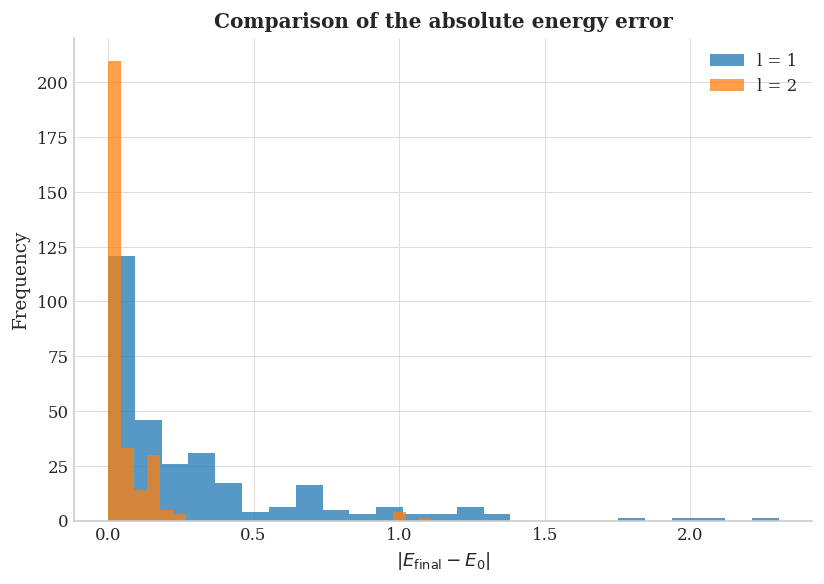

In [4]:
plt.figure(figsize=(7,5))

plt.hist(df1["diferencia_ground"], bins=25, alpha=0.75, label="l = 1")
plt.hist(df2["diferencia_ground"], bins=25, alpha=0.75, label="l = 2")

plt.xlabel(r"$|E_{\mathrm{final}} - E_0|$")
plt.ylabel("Frequency")
plt.title("Comparison of the absolute energy error")

plt.legend()
plt.tight_layout()
plt.show()


**Analysis:** `l=2` drastically reduces the energy error relative to `l=1`. The mean error drops from $0.292$ to $0.056$ (5× lower) and the median from $0.151$ to $0.010$ (15× lower). However, both distributions show a tail toward large errors (max. $2.30$ for `l=1` and $1.11$ for `l=2`), indicating that there are difficult instances that neither pool solves well. The `l=2` histogram is much more concentrated near zero, but it is not free of occasional failures.

### 2. Cumulative distribution function (CDF) of the error

**What it shows:**
The cumulative fraction of instances that reach an error below a given threshold.

**How to interpret it:**
- x-axis (log scale): energy tolerance.
- y-axis: proportion of graphs that meet that tolerance.
- Example:
  - If at $10^{-3}$ the curve is at 0.8 → 80% of the instances have an error below $10^{-3}$.

**Why it matters:**
It allows evaluating the **robustness of the algorithm** across the whole set of instances.

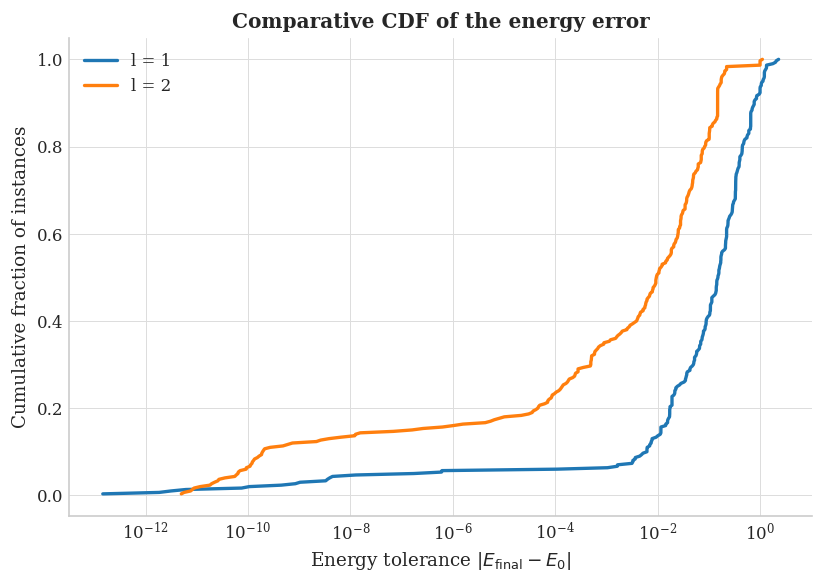

In [5]:
# Take absolute errors
errors1 = np.sort(df1["diferencia_ground"].dropna().values)  # l = 1
cdf1 = np.arange(1, len(errors1) + 1) / len(errors1)

errors2 = np.sort(df2["diferencia_ground"].dropna().values)  # l = 2
cdf2 = np.arange(1, len(errors2) + 1) / len(errors2)

plt.figure(figsize=(7,5))

plt.plot(errors1, cdf1, label="l = 1")
plt.plot(errors2, cdf2, label="l = 2")

plt.xscale("log")
plt.xlabel(r"Energy tolerance $|E_{\mathrm{final}} - E_0|$")
plt.ylabel("Cumulative fraction of instances")
plt.title("Comparative CDF of the energy error")

plt.legend()
plt.tight_layout()
plt.show()


**Analysis:** The CDF confirms the systematic advantage of `l=2` across the whole tolerance range. At tolerance $10^{-2}$, `l=2` reaches approximately 50% of the graphs while `l=1` barely exceeds 13%. The `l=2` curve is consistently shifted to the left, which means that for any required precision threshold, `l=2` solves a larger fraction of instances. The gap between both curves is especially pronounced at strict tolerances ($< 10^{-1}$), where the extended pool makes a real difference.


### 3. Distribution of the number of iterations

**What it shows:**
Number of iterations (or ansatz size) the algorithm requires to converge.

**How to interpret it:**
- Low values → the algorithm converges quickly.
- Wide distributions → variability in the difficulty of the graphs.
- Peaks → typical behavior of the algorithm.

**Physical interpretation:**
The number of iterations corresponds to the number of operators added in ADAPT-VQE.

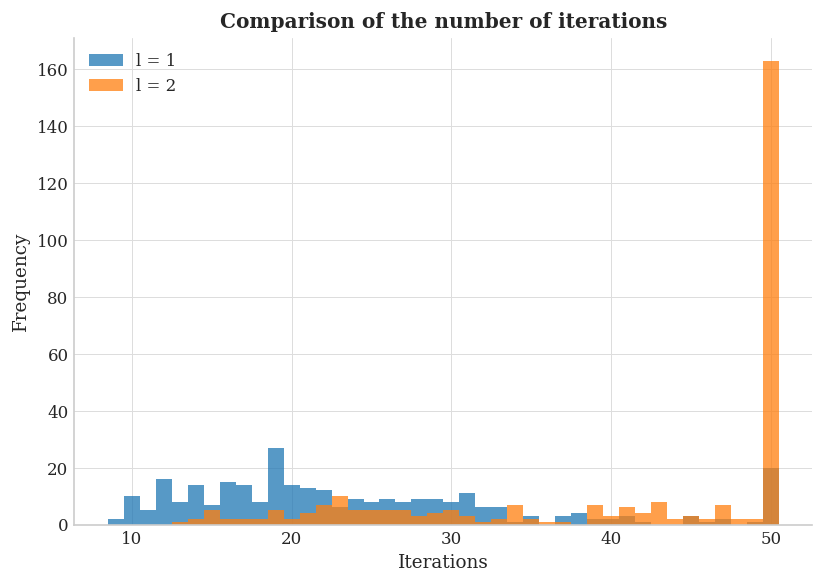

In [6]:
plt.figure(figsize=(7,5))

# common bins
min_iter = min(df1["iteraciones"].min(), df2["iteraciones"].min())
max_iter = max(df1["iteraciones"].max(), df2["iteraciones"].max())
bins = np.arange(min_iter, max_iter + 2) - 0.5

plt.hist(df1["iteraciones"], bins=bins, alpha=0.75, label="l = 1")
plt.hist(df2["iteraciones"], bins=bins, alpha=0.75, label="l = 2")

plt.xlabel("Iterations")
plt.ylabel("Frequency")
plt.title("Comparison of the number of iterations")

plt.legend()
plt.tight_layout()
plt.show()


**Analysis:** `l=2` requires significantly more iterations to converge: a mean of $41.3$ versus $24.2$ for `l=1`. Many graphs with `l=2` reach the 50-iteration limit without converging, which suggests that the extended pool, while more expressive, takes more iterations to find the right direction. `l=1`, with a smaller pool, converges more consistently and predictably. This is relevant for evaluating the algorithm's real efficiency: the higher accuracy of `l=2` comes at the cost of a deeper ansatz.

### 4. Average convergence curve of the energy error

**Definition:**
$$
\Delta E_k = |E_k - E_0|
$$

**What it shows:**
The evolution of the energy error over the algorithm's iterations.

**Plot components:**
- Mean → average behavior.
- Median → typical behavior.
- Band (25%-75%) → variability across instances.

**How to interpret it:**
- Fast decrease → good initial efficiency.
- Plateau → region where the algorithm stops improving.
- Wide band → variability across graphs.

**Importance:**
This plot shows the algorithm's internal dynamics and its convergence capability.

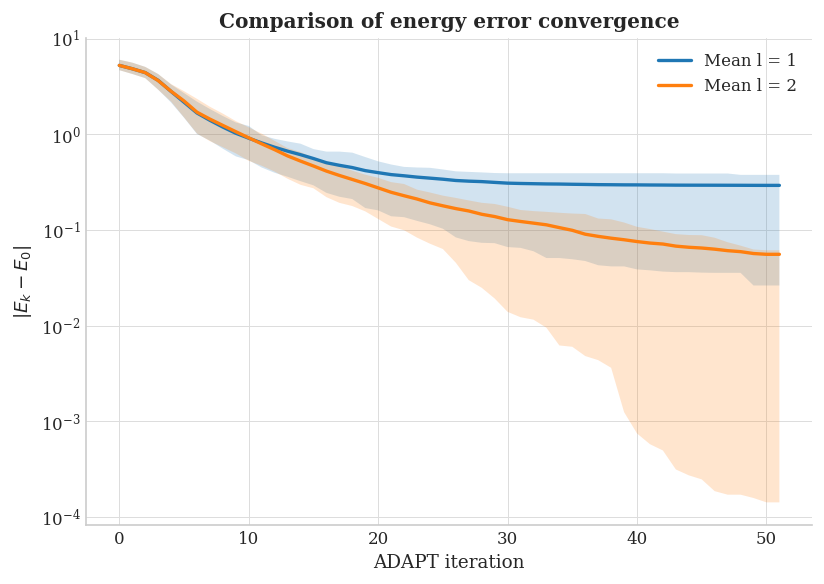

In [7]:
stats_l1 = compute_error_stats([
    "results/json/resultados_completos_n6_l1_1_300.json"
])

stats_l2 = compute_error_stats([
    "results/json/resultados_completos_n6_l2_1_300.json"
])

plt.figure(figsize=(7,5))

x1 = np.arange(stats_l1["len"])
x2 = np.arange(stats_l2["len"])

# means
plt.plot(x1, stats_l1["mean"], label="Mean l = 1")
plt.plot(x2, stats_l2["mean"], label="Mean l = 2")

# interquartile bands
plt.fill_between(x1, stats_l1["q25"], stats_l1["q75"], alpha=0.2)
plt.fill_between(x2, stats_l2["q25"], stats_l2["q75"], alpha=0.2)

plt.yscale("log")
plt.xlabel("ADAPT iteration")
plt.ylabel(r"$|E_k - E_0|$")
plt.title("Comparison of energy error convergence")

plt.legend()
plt.tight_layout()
plt.show()


**Analysis:** Both algorithms show a fast initial decrease of the average error, followed by a plateau. `l=2` reaches significantly lower average errors than `l=1` before stalling, which confirms that the extended pool converges to better minima. The interquartile band of `l=2` is narrower in the later iterations, indicating lower variability across graphs once the algorithm has progressed. The pronounced plateau in both cases at high iterations suggests diminishing returns: past a certain point, adding operators yields less and less improvement.

### 5. Approximation ratio for Max-3-Cut

**Definition:**
$$
r = \frac{C_{\text{final}}}{C_{\max}} = \frac{E_{\text{final}}}{E_0} \in (0, 1]
$$
where $C_{max}$ is the exact maximum cut and $C_{final}$ is the cut obtained by the algorithm.

**What it shows:**
The histogram compares the distribution of the approximation ratio between `l=1` and `l=2`. The complementary CDF shows what fraction of graphs reach a ratio **greater than or equal to** a given threshold.

**How to interpret it:**
- $r = 1$ → exact solution.
- $r \geq 0.99$ → solution within 1% of the optimum.
- The **higher and further-right complementary CDF** curve corresponds to the better algorithm: at the same threshold, more graphs reach it.
- This metric is more interpretable than the absolute error because it is normalized by problem size and is directly comparable to benchmarks from the combinatorial optimization literature.

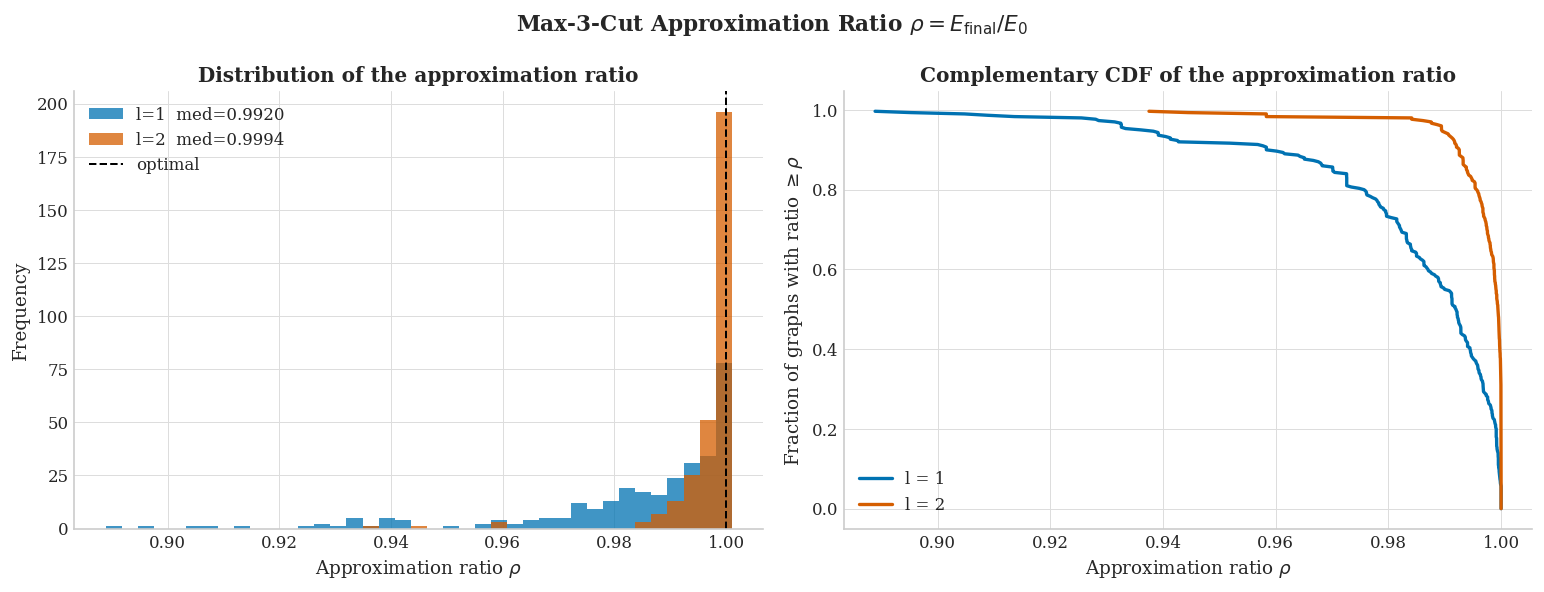

l=1 | mean=0.98439  median=0.99202  min=0.88888
l=2 | mean=0.99711  median=0.99945  min=0.93750

Graphs with ratio >= 0.99:  l=1 → 55.0%  |  l=2 → 94.7%


In [8]:
# Approximation ratio for Max-3-Cut: C_final / C_max
# C_max = -E0 / 2,  C_final = -E_final / 2  →  ratio = E_final / E0

approx_ratio_l1 = np.array([
    data_l1[g]["final_energy"] / data_l1[g]["ground_energy"]
    for g in common_ids
])
approx_ratio_l2 = np.array([
    data_l2[g]["final_energy"] / data_l2[g]["ground_energy"]
    for g in common_ids
])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Compared histograms
ax = axes[0]
bins = np.linspace(min(approx_ratio_l1.min(), approx_ratio_l2.min()), 1.001, 40)
ax.hist(approx_ratio_l1, bins=bins, alpha=0.75, color=C1,
        label=f"l=1  med={np.median(approx_ratio_l1):.4f}")
ax.hist(approx_ratio_l2, bins=bins, alpha=0.75, color=C2,
        label=f"l=2  med={np.median(approx_ratio_l2):.4f}")
ax.axvline(1.0, color="black", linestyle="--", linewidth=1.2, label="optimal")
ax.set_xlabel(r"Approximation ratio $\rho$")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of the approximation ratio")
ax.legend()

# CDF
ax = axes[1]
for ratio, label, color in [
    (approx_ratio_l1, "l = 1", C1),
    (approx_ratio_l2, "l = 2", C2),
]:
    sorted_r = np.sort(ratio)
    cdf = np.arange(1, len(sorted_r) + 1) / len(sorted_r)
    ax.plot(sorted_r, 1 - cdf, color=color, linewidth=2, label=label)

ax.set_xlabel(r"Approximation ratio $\rho$")
ax.set_ylabel(r"Fraction of graphs with ratio $\geq \rho$")
ax.set_title("Complementary CDF of the approximation ratio")
ax.legend()

plt.suptitle(r"Max-3-Cut Approximation Ratio $\rho = E_{\mathrm{final}} / E_0$",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"l=1 | mean={np.mean(approx_ratio_l1):.5f}  "
      f"median={np.median(approx_ratio_l1):.5f}  "
      f"min={np.min(approx_ratio_l1):.5f}")
print(f"l=2 | mean={np.mean(approx_ratio_l2):.5f}  "
      f"median={np.median(approx_ratio_l2):.5f}  "
      f"min={np.min(approx_ratio_l2):.5f}")
print(f"\nGraphs with ratio >= 0.99:  l=1 → {np.mean(approx_ratio_l1 >= 0.99)*100:.1f}%  "
      f"|  l=2 → {np.mean(approx_ratio_l2 >= 0.99)*100:.1f}%")


**Analysis:** `l=2` achieves a median approximation ratio of $0.9994$ versus $0.992$ for `l=1`, and 94.7% of its graphs reach a ratio $\geq 0.99$ versus only 55.0% for `l=1`. In terms of the optimization problem, `l=2` finds solutions within 1% of the optimum on virtually every graph. `l=1`, on the other hand, fails on nearly half of the instances. The minimum for `l=1` drops to $0.889$, meaning that some graphs only reach 89% of the optimal cut, a non-negligible margin in a combinatorial optimization problem.

### 6. Marginal energy improvement per iteration

**Definition:**
$$
\Delta E_k = E_{k-1} - E_k \geq 0
$$
is the energy reduction contributed by the $k$-th operator added to the ansatz.

**What it shows:**
The average gain (and its variability) that each new ADAPT iteration produces. The y-axis uses a symlog scale to simultaneously show large and small improvements.

**How to interpret it:**
- The first iterations should have large $\Delta E_k$: the algorithm learns fast at the beginning.
- A fast decay toward zero indicates **diminishing returns**: adding more operators stops improving the solution.
- If $\Delta E_k \approx 0$ before the gradient converges, the algorithm is stuck in a local minimum.
- Comparing `l=1` and `l=2`: if `l=2` has larger $\Delta E_k$ in the early iterations, the extended pool gives "better first steps".

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5720\2135558628.py:76: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


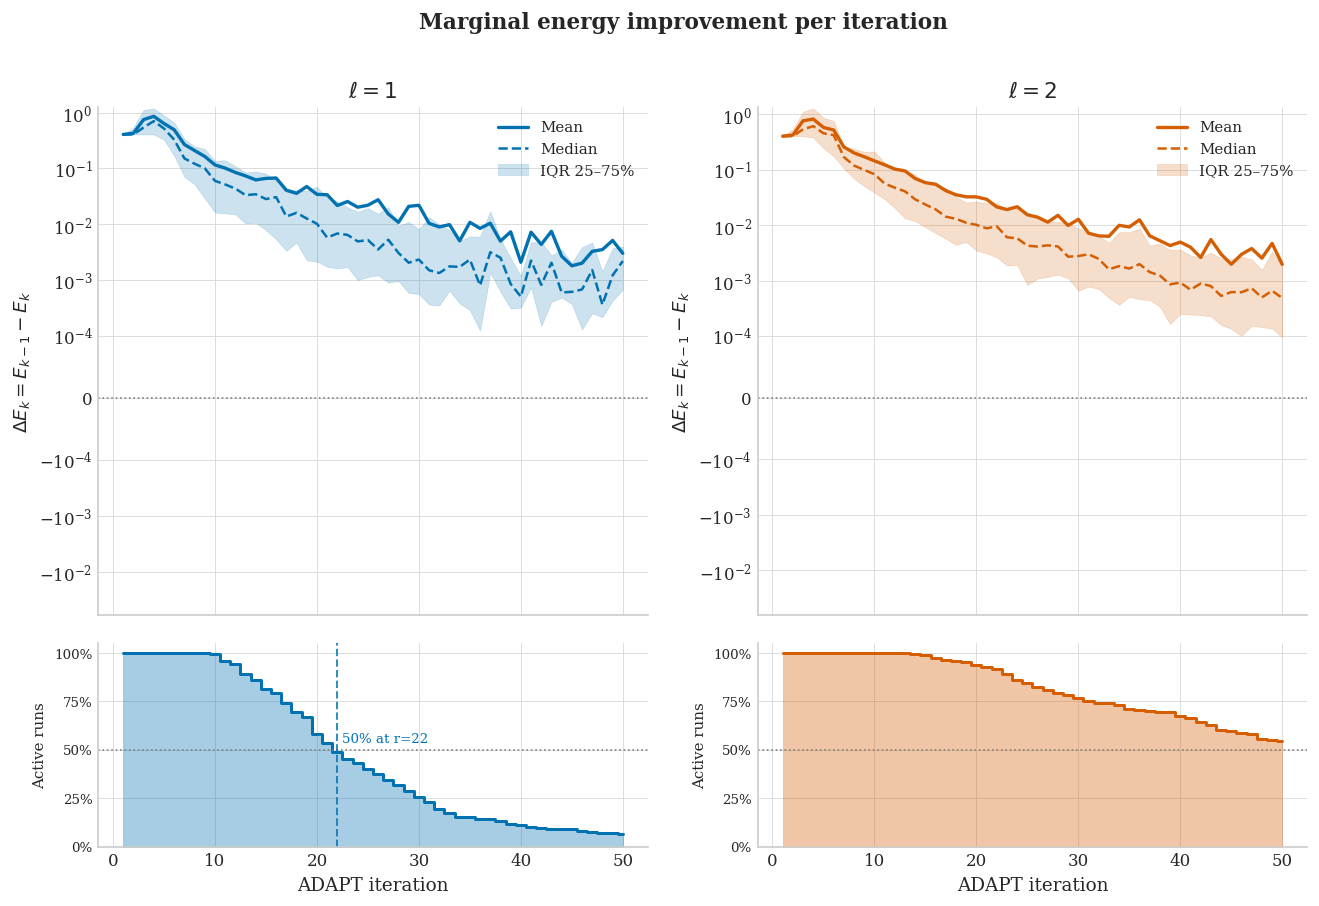

In [9]:
# Marginal improvement per iteration + fraction of active runs (2 rows x 2 columns)
def compute_marginal_stats(data_dict):
    all_deltas = []
    max_iters  = max(item['iterations'] for item in data_dict.values())
    for item in data_dict.values():
        trace  = np.array(item['energy_trace'], dtype=float)[:-1]
        deltas = np.diff(-trace)   # positive when the energy decreases
        all_deltas.append(deltas)
    padded = np.full((len(all_deltas), max_iters), np.nan)
    for i, d in enumerate(all_deltas):
        padded[i, :len(d)] = d
    n_active = np.sum(~np.isnan(padded), axis=0)
    return {
        'mean'    : np.nanmean(padded, axis=0),
        'median'  : np.nanmedian(padded, axis=0),
        'q25'     : np.nanpercentile(padded, 25, axis=0),
        'q75'     : np.nanpercentile(padded, 75, axis=0),
        'n_active': n_active,
        'frac_active': n_active / len(all_deltas),
    }

marg_l1 = compute_marginal_stats(data_l1)
marg_l2 = compute_marginal_stats(data_l2)
N_TOTAL = len(data_l1)   # 300

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 8),
    gridspec_kw={'height_ratios': [3, 1.2], 'hspace': 0.08},
    sharex='col',
)

for col, (marg, label, color) in enumerate([
    (marg_l1, '$\ell = 1$', C1),
    (marg_l2, '$\ell = 2$', C2),
]):
    ax_top = axes[0, col]
    ax_bot = axes[1, col]
    x = np.arange(1, len(marg['mean']) + 1)

    # ── Top panel: marginal improvement ──
    ax_top.plot(x, marg['mean'],   color=color, linewidth=2,   label='Mean')
    ax_top.plot(x, marg['median'], color=color, linewidth=1.5,
                linestyle='--', label='Median')
    ax_top.fill_between(x, marg['q25'], marg['q75'],
                        color=color, alpha=0.20, label='IQR 25–75%')
    ax_top.axhline(0, color='gray', linestyle=':', linewidth=1)
    ax_top.set_ylabel(r'$\Delta E_k = E_{k-1} - E_k$')
    ax_top.set_yscale('symlog', linthresh=1e-4)
    ax_top.set_title(label, fontsize=13)
    ax_top.legend(fontsize=9)
    ax_top.tick_params(labelbottom=False)

    # ── Bottom panel: fraction of active runs ──
    frac = marg['frac_active'] * 100   # percentage
    ax_bot.fill_between(x, 0, frac, color=color, alpha=0.35, step='mid')
    ax_bot.step(x, frac, color=color, linewidth=1.8, where='mid')
    ax_bot.axhline(50, color='gray', linestyle=':', linewidth=1)
    ax_bot.set_ylim(0, 105)
    ax_bot.set_yticks([0, 25, 50, 75, 100])
    ax_bot.set_yticklabels(['0%', '25%', '50%', '75%', '100%'], fontsize=8)
    ax_bot.set_ylabel('Active runs', fontsize=9)
    ax_bot.set_xlabel('ADAPT iteration')

    # Annotate where each pool loses half of its runs
    half_iter = np.searchsorted(-frac, -50)
    if half_iter < len(x):
        ax_bot.axvline(x[half_iter], color=color, linewidth=1.2,
                       linestyle='--', alpha=0.8)
        ax_bot.text(x[half_iter] + 0.5, 54,
                    f'50% at r={x[half_iter]}',
                    fontsize=8, color=color)

fig.suptitle('Marginal energy improvement per iteration',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Analysis:** Both algorithms exhibit clear diminishing returns: the marginal improvement $\Delta E_k$ is large in the first iterations and decays quickly. What stands out is that `l=2` keeps positive marginal improvements for more iterations before stalling, which explains why it reaches lower energies. `l=1` flattens out faster, consistent with its lower number of iterations. The wide interquartile band in the early iterations indicates high variability across graphs in the first energy "jump", while in late iterations the graphs behave more homogeneously.

### 7. Does `l=2` really use the $O_3$ operators?

**What it shows:**
For the `l=2` pool, which contains operators from $O_1$ and $O_3$, this analysis measures what fraction of the operators **actually selected** by ADAPT come from $O_3$ (the new ones from the extended pool) versus $O_1$ (which `l=1` also has).

**How to interpret it:**
- **Left pie chart**: global ansatz composition aggregating the 300 graphs. If $O_3$ has a low percentage, the extended pool contributes little in practice.
- **Right histogram**: per-graph distribution of the fraction of $O_3$ used. If most graphs have a fraction close to 0, it means $O_3$ operators are almost never selected.
- If the mean fraction of $O_3$ is high → `l=2` really exploits the extended pool.
- If the fraction is low → `l=2` converges mainly using the same operators as `l=1`, and the benefit of the extended pool is marginal.

**Why it matters:**
This is the central question to justify `l=2`: if the algorithm does not select $O_3$ operators, the extra cost of the larger pool does not translate into a real improvement.

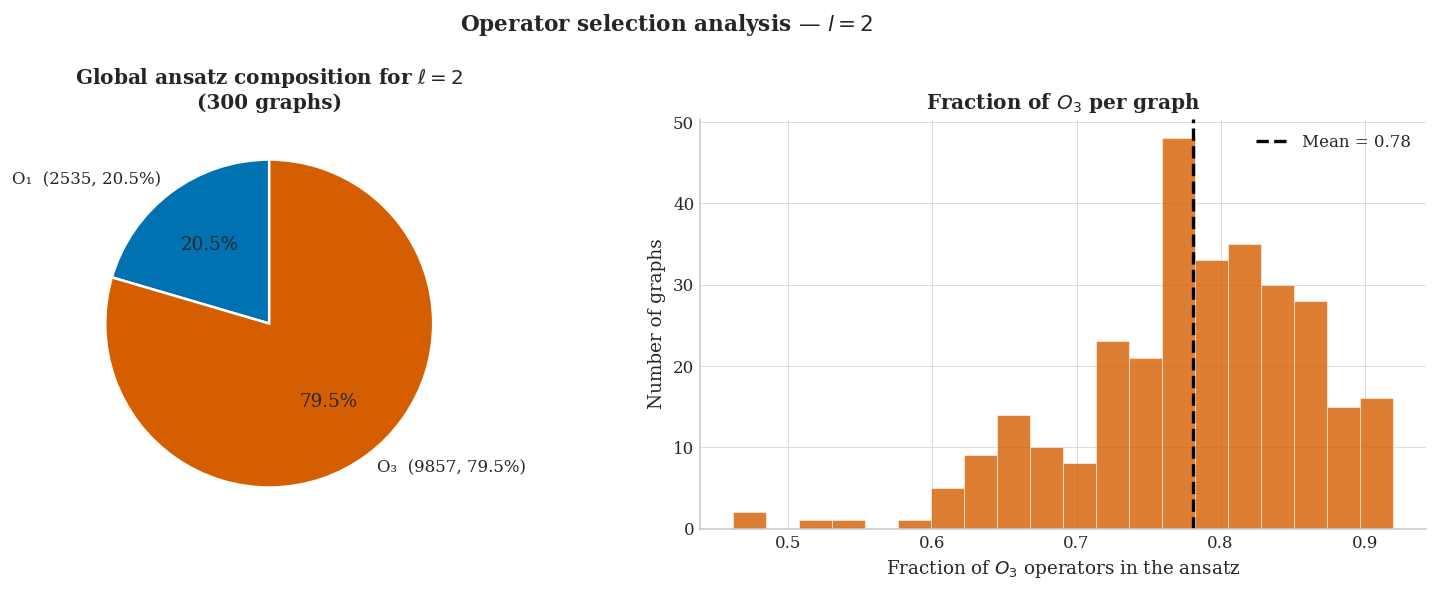

Total selections: 12392  |  O1: 2535 (20.5%)  |  O3: 9857 (79.5%)
Mean O3 fraction per graph: 0.781  ±  0.080


In [10]:
# Does l=2 use the O3 operators? Operator selection analysis
from collections import Counter

# For each graph, the pool_labels of l=1 are exactly the O1 operators.
# In l=2, pool_labels = O1_labels + O3_labels.
# We compare the ansatz_op_labels of l=2 against the l=1 pool to classify them.

count_o1, count_o3 = 0, 0
per_graph_frac_o3 = []

for gid in common_ids:
    pool_l1  = set(data_l1[gid].get("pool_labels", []))
    selected = data_l2[gid].get("ansatz_op_labels", [])

    n_o1 = sum(1 for lbl in selected if lbl in pool_l1)
    n_o3 = len(selected) - n_o1
    count_o1 += n_o1
    count_o3 += n_o3

    if len(selected) > 0:
        per_graph_frac_o3.append(n_o3 / len(selected))

per_graph_frac_o3 = np.array(per_graph_frac_o3)
total = count_o1 + count_o3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left panel: global pie chart
ax = axes[0]
ax.pie([count_o1, count_o3],
       labels=[f"O₁  ({count_o1}, {100*count_o1/total:.1f}%)",
               f"O₃  ({count_o3}, {100*count_o3/total:.1f}%)"],
       colors=[C1, C2],
       autopct="%1.1f%%", startangle=90,
       wedgeprops=dict(edgecolor="white", linewidth=1.5))
ax.set_title("Global ansatz composition for $\ell=2$\n(300 graphs)")

# Right panel: histogram of O3 fraction per graph
ax = axes[1]
ax.hist(per_graph_frac_o3, bins=20, color=C2, alpha=0.8, edgecolor="white")
ax.axvline(np.mean(per_graph_frac_o3), color="black", linestyle="--",
           label=f"Mean = {np.mean(per_graph_frac_o3):.2f}")
ax.set_xlabel("Fraction of $O_3$ operators in the ansatz")
ax.set_ylabel("Number of graphs")
ax.set_title("Fraction of $O_3$ per graph")
ax.legend()

plt.suptitle(r"Operator selection analysis — $l=2$",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Total selections: {total}  |  O1: {count_o1} ({100*count_o1/total:.1f}%)  "
      f"|  O3: {count_o3} ({100*count_o3/total:.1f}%)")
print(f"Mean O3 fraction per graph: {np.mean(per_graph_frac_o3):.3f}  "
      f"±  {np.std(per_graph_frac_o3):.3f}")


**Analysis:** This is one of the most revealing results. In `l=2`, **79.5%** of the operators selected by ADAPT come from the $O_3$ pool (the extended pool), with a mean fraction per graph of $0.78 \pm 0.08$. This means that when given access to the extended pool, the algorithm overwhelmingly prefers $O_3$ operators over $O_1$ ones. The per-graph histogram shows a distribution tightly concentrated around 75-85%, with little variability across instances. This suggests that $O_3$ operators systematically have higher gradients than $O_1$ ones under the problem's conditions, making them more "attractive" for ADAPT at each step. The practical implication is that `l=1` and `l=2` are traversing completely different paths in operator space.

### 8. Distribution of the optimized parameters $\theta$

**What it shows:**
The histogram of all final $\theta_k$ values of the ansatz, collected over the 300 graphs.

**How to interpret it:**
- A distribution concentrated around a specific value suggests that the algorithm converges to a **universal** ansatz structure, independent of the graph.
- A very spread-out distribution indicates that parameters vary a lot across instances, implying greater difficulty in generalizing.
- If `l=1` and `l=2` have similar distributions, the additional $O_3$ operators do not change the profile of the selected angles.
- Values concentrated near zero may indicate that some operators are redundant.

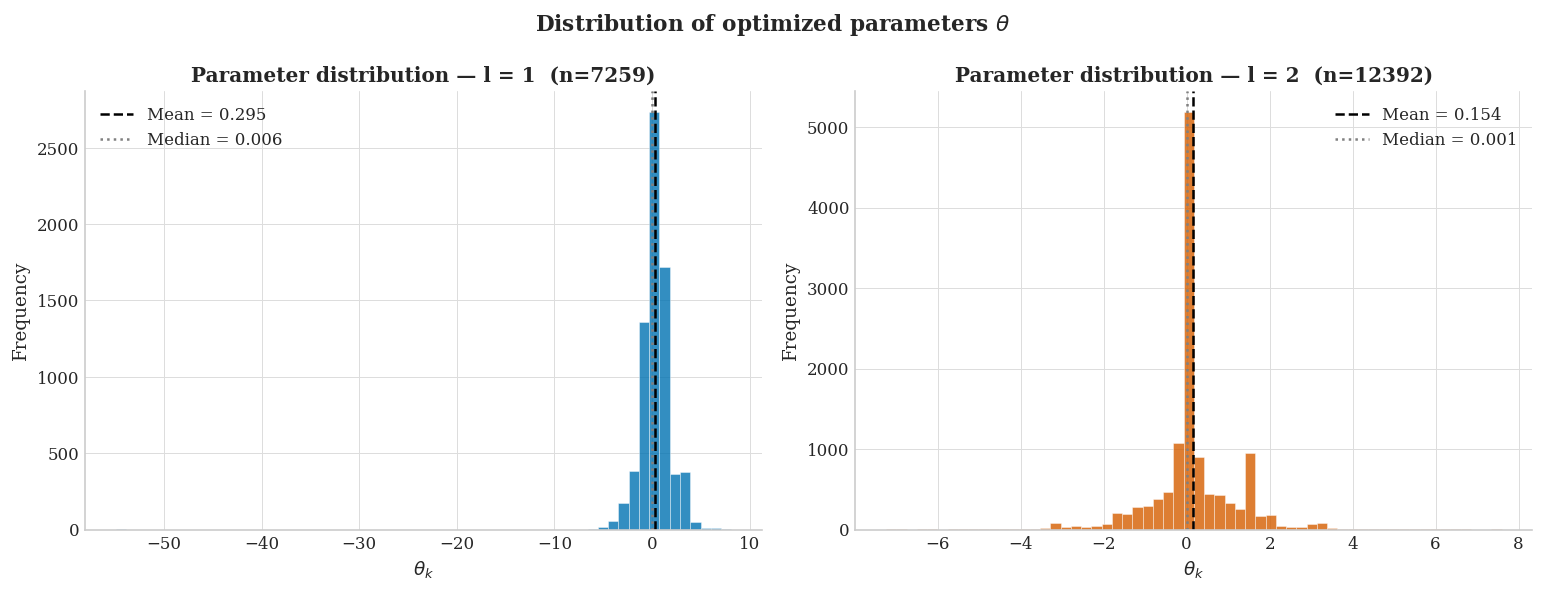

l=1 | mean=0.2948  std=1.5950  min=-54.9524  max=8.1304
l=2 | mean=0.1541  std=1.0052  min=-7.2444  max=7.5920


In [11]:
# Distribution of the final theta parameters
all_params_l1, all_params_l2 = [], []

for item in data_l1.values():
    all_params_l1.extend(item.get("params", []))
for item in data_l2.values():
    all_params_l2.extend(item.get("params", []))

all_params_l1 = np.array(all_params_l1)
all_params_l2 = np.array(all_params_l2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, params, label, color in [
    (axes[0], all_params_l1, "l = 1", C1),
    (axes[1], all_params_l2, "l = 2", C2),
]:
    ax.hist(params, bins=60, color=color, alpha=0.8, edgecolor="white", linewidth=0.3)
    ax.axvline(np.mean(params),   color="black", linestyle="--", linewidth=1.5,
               label=f"Mean = {np.mean(params):.3f}")
    ax.axvline(np.median(params), color="gray",  linestyle=":",  linewidth=1.5,
               label=f"Median = {np.median(params):.3f}")
    ax.set_xlabel(r"$\theta_k$")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Parameter distribution — {label}  (n={len(params)})")
    ax.legend()

plt.suptitle(r"Distribution of optimized parameters $\theta$",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"l=1 | mean={np.mean(all_params_l1):.4f}  "
      f"std={np.std(all_params_l1):.4f}  "
      f"min={np.min(all_params_l1):.4f}  max={np.max(all_params_l1):.4f}")
print(f"l=2 | mean={np.mean(all_params_l2):.4f}  "
      f"std={np.std(all_params_l2):.4f}  "
      f"min={np.min(all_params_l2):.4f}  max={np.max(all_params_l2):.4f}")


**Analysis:** The pronounced peak at $\theta \approx 0$ is an **expected and healthy** behavior of the ADAPT algorithm. It does not indicate that the operators are redundant, but reflects the ansatz's **hierarchical structure**: the first operators do the heavy lifting (large angles) and later ones only apply fine corrections (small angles). Moreover, BFGS re-optimizes *all* parameters simultaneously at each iteration, so a parameter that used to be large can become small once a later operator takes its place in the descent direction. A large number of $\theta \approx 0$ would only be problematic if the zero-angle operators were also the last ones added, which would indicate that the algorithm keeps iterating without providing real improvements (a threshold $\varepsilon$ problem).

The most relevant difference between the two pools is the **left tail of `l=1`** (min. $-54.95$ vs. $-7.24$ for `l=2`). The $O_1$ operators have a flatter and more periodic optimization landscape: BFGS can move large distances without penalty, which in some graphs leads to extremely large angles that may correspond to local minima. `l=2`, by including $O_3$ operators that point directly in the quantum descent direction, finds smaller and more consistent angles (std $=1.01$ vs. $1.60$), reflecting a more regular optimization landscape.

## Analysis: common budget

To make a fair comparison between `l=1` and `l=2`, the number of iterations of both is equalized to that of the algorithm that converges first: for each graph $r_{common} = \min(r_{l=1}, r_{l=2})$ is computed and both traces are truncated at that point. So, if `l=1` converges in 20 iterations and `l=2` in 44, both are evaluated with only 20 operators in the ansatz — this removes the artificial advantage that the algorithm using more iterations would otherwise have.

Unlike the normal case (where each algorithm runs to its own convergence), here whichever converges first "stops" the other. The analyses below are identical to those of the normal case, but on the truncated data.

### 0. Data loading

In [12]:
from pathlib import Path

# ============================================================
# OUTPUT FILES
# ============================================================

OUTPUT_L1_CSV = Path("results/csv/resultados_resumen_n6_l1_common_budget.csv")
OUTPUT_L1_JSON = Path("results/json/resultados_completos_n6_l1_common_budget.json")

OUTPUT_L2_CSV = Path("results/csv/resultados_resumen_n6_l2_common_budget.csv")
OUTPUT_L2_JSON = Path("results/json/resultados_completos_n6_l2_common_budget.json")


# ============================================================
# MAIN EXECUTION
# ============================================================

# We reuse data_l1/data_l2 (complete, unrestricted JSON) already
# loaded in "Analysis: free convergence" — avoids re-reading the same
# files again.
l1_by_id = data_l1
l2_by_id = data_l2

controlled_l1 = []
controlled_l2 = []
budget_info = []
errors = []

for grafo_id in sorted(l1_by_id.keys()):

    if grafo_id not in l2_by_id:
        error_msg = f"grafo_id={grafo_id} not found in l=2."

        controlled_l1.append({
            "grafo_id": grafo_id,
            "error": error_msg
        })

        controlled_l2.append({
            "grafo_id": grafo_id,
            "error": error_msg
        })

        errors.append((grafo_id, error_msg))
        continue

    try:
        r_l1 = get_num_ops(l1_by_id[grafo_id])
        r_l2 = get_num_ops(l2_by_id[grafo_id])

        r_common = min(r_l1, r_l2)

        item_l1 = truncate_result_to_budget(
            result=l1_by_id[grafo_id],
            r_common=r_common
        )

        item_l2 = truncate_result_to_budget(
            result=l2_by_id[grafo_id],
            r_common=r_common
        )

        item_l1["grafo_id"] = grafo_id
        item_l2["grafo_id"] = grafo_id

        controlled_l1.append(item_l1)
        controlled_l2.append(item_l2)

        budget_info.append({
            "grafo_id": grafo_id,
            "r_l1_original": r_l1,
            "r_l2_original": r_l2,
            "r_common": r_common
        })

    except Exception as e:
        error_msg = str(e)

        controlled_l1.append({
            "grafo_id": grafo_id,
            "error": error_msg
        })

        controlled_l2.append({
            "grafo_id": grafo_id,
            "error": error_msg
        })

        errors.append((grafo_id, error_msg))


# ============================================================
# SAVE FILES
# ============================================================

save_json(controlled_l1, OUTPUT_L1_JSON)
save_json(controlled_l2, OUTPUT_L2_JSON)

save_csv(controlled_l1, OUTPUT_L1_CSV)
save_csv(controlled_l2, OUTPUT_L2_CSV)


# ============================================================
# VERIFICATION
# ============================================================

mismatches = []

for item_l1, item_l2 in zip(controlled_l1, controlled_l2):

    if "error" in item_l1 or "error" in item_l2:
        continue

    if int(item_l1["iterations"]) != int(item_l2["iterations"]):
        mismatches.append(
            (
                item_l1["grafo_id"],
                item_l1["iterations"],
                item_l2["iterations"]
            )
        )

print("\nFiles saved:")
print(f"  {OUTPUT_L1_CSV}")
print(f"  {OUTPUT_L1_JSON}")
print(f"  {OUTPUT_L2_CSV}")
print(f"  {OUTPUT_L2_JSON}")

print(f"\nResults processed: {len(controlled_l1)}")
print(f"Errors: {len(errors)}")

if errors:
    print("\nFirst errors:")
    for err in errors[:20]:
        print(err)

if len(mismatches) == 0:
    print("\nVerification passed: l=1 and l=2 have the same number of iterations per graph.")
else:
    print("\nThere are differences in iterations:")
    for item in mismatches[:20]:
        print(item)

print("\nFirst common budgets:")
for item in budget_info[:10]:
    print(item)

# ============================================================
# IN-MEMORY STRUCTURES (avoids re-reading the files just saved)
# ============================================================

data_l1 = {item["grafo_id"]: item for item in controlled_l1 if "error" not in item}
data_l2 = {item["grafo_id"]: item for item in controlled_l2 if "error" not in item}

def _resumen_row(item):
    return {
        "grafo_id": item["grafo_id"],
        "num_edges": item["num_edges"],
        "ground_energy": item["ground_energy"],
        "iteraciones": item["iterations"],
        "energia_final": item["final_energy"],
        "diferencia_ground": item["difference_ground"],
        "gradiente_final": item["final_gradient_norm"],
        "runtime_min": item["runtime_min"],
        "initial_energy": item["initial_energy"],
    }

df1_controled = pd.DataFrame([_resumen_row(item) for item in controlled_l1 if "error" not in item])
df2_controled = pd.DataFrame([_resumen_row(item) for item in controlled_l2 if "error" not in item])



Files saved:
  results\csv\resultados_resumen_n6_l1_common_budget.csv
  results\json\resultados_completos_n6_l1_common_budget.json
  results\csv\resultados_resumen_n6_l2_common_budget.csv
  results\json\resultados_completos_n6_l2_common_budget.json

Results processed: 300
Errors: 0

Verification passed: l=1 and l=2 have the same number of iterations per graph.

First common budgets:
{'grafo_id': 1, 'r_l1_original': 20, 'r_l2_original': 44, 'r_common': 20}
{'grafo_id': 2, 'r_l1_original': 12, 'r_l2_original': 34, 'r_common': 12}
{'grafo_id': 3, 'r_l1_original': 12, 'r_l2_original': 50, 'r_common': 12}
{'grafo_id': 4, 'r_l1_original': 21, 'r_l2_original': 27, 'r_common': 21}
{'grafo_id': 5, 'r_l1_original': 20, 'r_l2_original': 30, 'r_common': 20}
{'grafo_id': 6, 'r_l1_original': 33, 'r_l2_original': 50, 'r_common': 33}
{'grafo_id': 7, 'r_l1_original': 15, 'r_l2_original': 50, 'r_common': 15}
{'grafo_id': 8, 'r_l1_original': 19, 'r_l2_original': 50, 'r_common': 19}
{'grafo_id': 9, 'r_l1

l=1 stopped first: 259/300 (86.3%)
l=2 stopped first: 19/300 (6.3%)
Tied (incl. both hit r_max=50): 22/300 (7.3%)


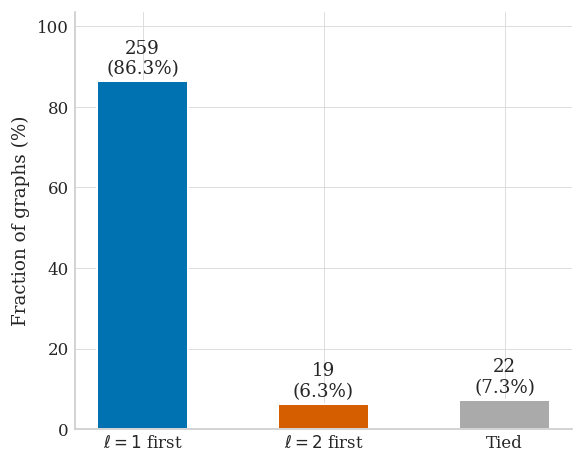

In [13]:
# Who set the common budget?
# Use df1 and df2 (original unrestricted data) to compare actual iteration counts
iters_l1 = df1.sort_values('grafo_id')['iteraciones'].values
iters_l2 = df2.sort_values('grafo_id')['iteraciones'].values
N = len(iters_l1)

n_l1_first = int(np.sum(iters_l1 < iters_l2))
n_l2_first = int(np.sum(iters_l2 < iters_l1))
n_tie      = int(np.sum(iters_l1 == iters_l2))

print(f'l=1 stopped first: {n_l1_first}/{N} ({100*n_l1_first/N:.1f}%)')
print(f'l=2 stopped first: {n_l2_first}/{N} ({100*n_l2_first/N:.1f}%)')
print(f'Tied (incl. both hit r_max=50): {n_tie}/{N} ({100*n_tie/N:.1f}%)')

labels = [r'$\ell=1$ first', r'$\ell=2$ first', 'Tied']
counts = [n_l1_first, n_l2_first, n_tie]
colors = [C1, C2, '#AAAAAA']

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(labels, [100*c/N for c in counts], color=colors,
              edgecolor='white', linewidth=1.2, width=0.5)

for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.8,
            f'{c}\n({100*c/N:.1f}%)',
            ha='center', va='bottom', fontsize=11)

ax.set_ylabel('Fraction of graphs (%)')
ax.set_ylim(0, max(100*c/N for c in counts) * 1.20)
#ax.set_title('Pool that converges first (common budget)')
plt.tight_layout()
plt.show()

**Analysis:** With a common budget, both algorithms use exactly the same number of iterations per graph (the minimum of the two), which makes the comparison strictly fair. The resulting distribution reflects the convergence of `l=1`, which is the faster algorithm on almost every graph (mean $24.2$ vs $41.3$). This implies that `l=2` is evaluated before completing its natural convergence.

### 1. Distribution of the absolute energy error — Common budget

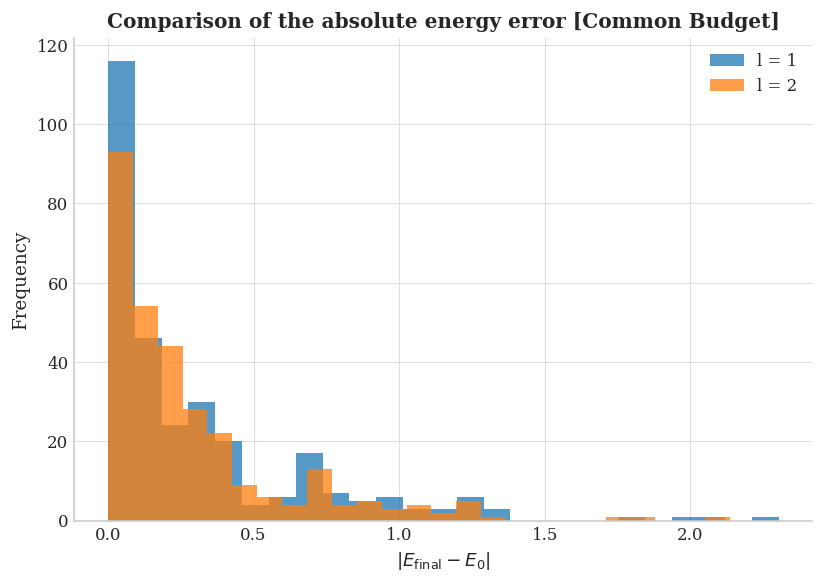

In [14]:
plt.figure(figsize=(7,5))

plt.hist(df1_controled["diferencia_ground"], bins=25, alpha=0.75, label="l = 1")
plt.hist(df2_controled["diferencia_ground"], bins=25, alpha=0.75, label="l = 2")

plt.xlabel(r"$|E_{\mathrm{final}} - E_0|$")
plt.ylabel("Frequency")
plt.title("Comparison of the absolute energy error [Common Budget]")

plt.legend()
plt.tight_layout()
plt.show()


**Analysis:** By equalizing the iteration budget, the error distributions of `l=1` and `l=2` become very similar. The advantage of `l=2` observed in the normal case practically disappears, revealing that its higher accuracy does not come from an intrinsic per-iteration superiority, but from using more iterations.

### 2. Cumulative distribution function (CDF) of the error — Common budget

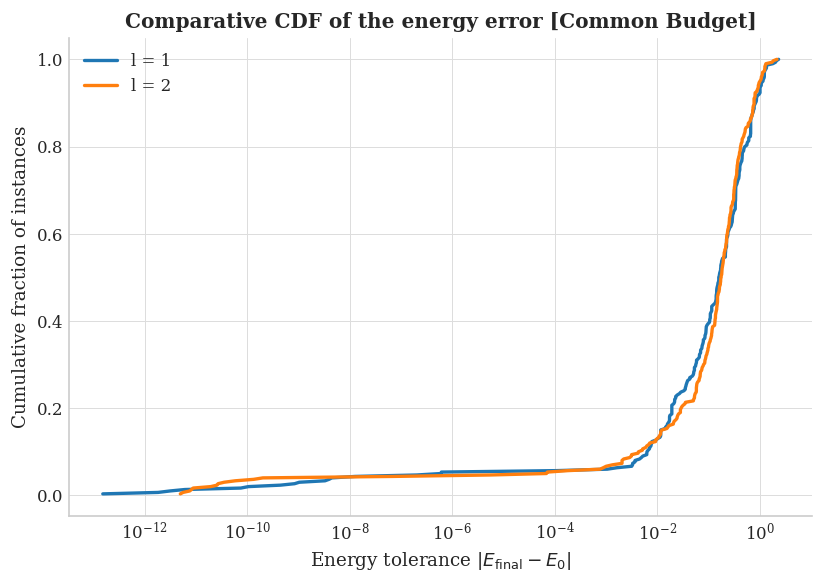

In [15]:
# Take absolute errors
errors1 = np.sort(df1_controled["diferencia_ground"].dropna().values)  # l = 1
cdf1 = np.arange(1, len(errors1) + 1) / len(errors1)

errors2 = np.sort(df2_controled["diferencia_ground"].dropna().values)  # l = 2
cdf2 = np.arange(1, len(errors2) + 1) / len(errors2)

plt.figure(figsize=(7,5))

plt.plot(errors1, cdf1, label="l = 1")
plt.plot(errors2, cdf2, label="l = 2")

plt.xscale("log")
plt.xlabel(r"Energy tolerance $|E_{\mathrm{final}} - E_0|$")
plt.ylabel("Cumulative fraction of instances")
plt.title("Comparative CDF of the energy error [Common Budget]")

plt.legend()
plt.tight_layout()
plt.show()


**Analysis:** The common-budget CDF confirms the tie between `l=1` and `l=2`: both curves overlap almost perfectly across the whole tolerance range. This contrasts sharply with the normal case, where `l=2` dominated by a wide margin. The result is conclusive: per iteration, `l=1` and `l=2` are equivalent.

### 4. Average convergence curve of the energy error — Common budget

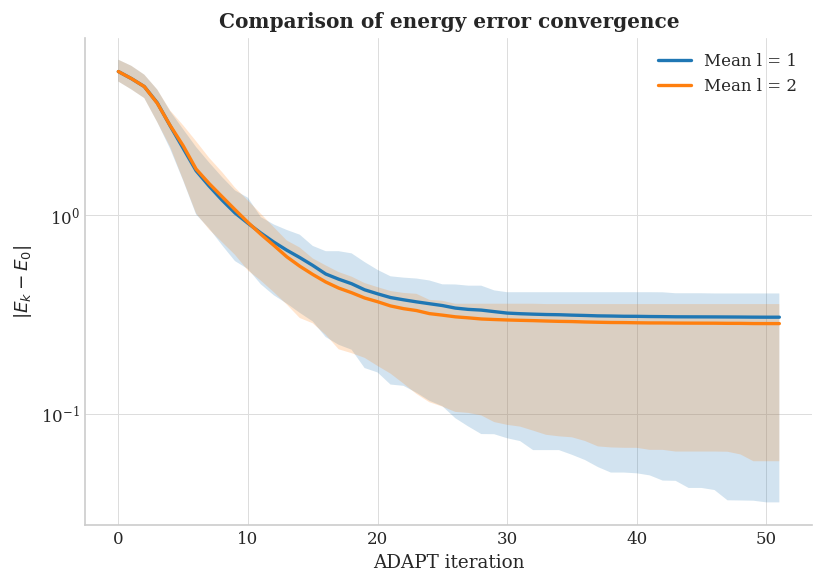

In [16]:
stats_l1 = compute_error_stats([
    "results/json/resultados_completos_n6_l1_common_budget.json"
])

stats_l2 = compute_error_stats([
    "results/json/resultados_completos_n6_l2_common_budget.json"
])

plt.figure(figsize=(7,5))

x1 = np.arange(stats_l1["len"])
x2 = np.arange(stats_l2["len"])

# means
plt.plot(x1, stats_l1["mean"], label="Mean l = 1")
plt.plot(x2, stats_l2["mean"], label="Mean l = 2")

# interquartile bands
plt.fill_between(x1, stats_l1["q25"], stats_l1["q75"], alpha=0.2)
plt.fill_between(x2, stats_l2["q25"], stats_l2["q75"], alpha=0.2)

plt.yscale("log")
plt.xlabel("ADAPT iteration")
plt.ylabel(r"$|E_k - E_0|$")
plt.title("Comparison of energy error convergence")

plt.legend()
plt.tight_layout()
plt.show()


**Analysis:** With a common budget, the convergence curves of `l=1` and `l=2` overlap almost perfectly, in contrast to the normal case where `l=2` reached lower errors. This confirms that the quality difference between the two pools arises only in the late iterations, which `l=2` reaches but `l=1` does not need because it has already converged. In the iteration range where both compete, they are indistinguishable.

### 5. Approximation ratio — Common budget

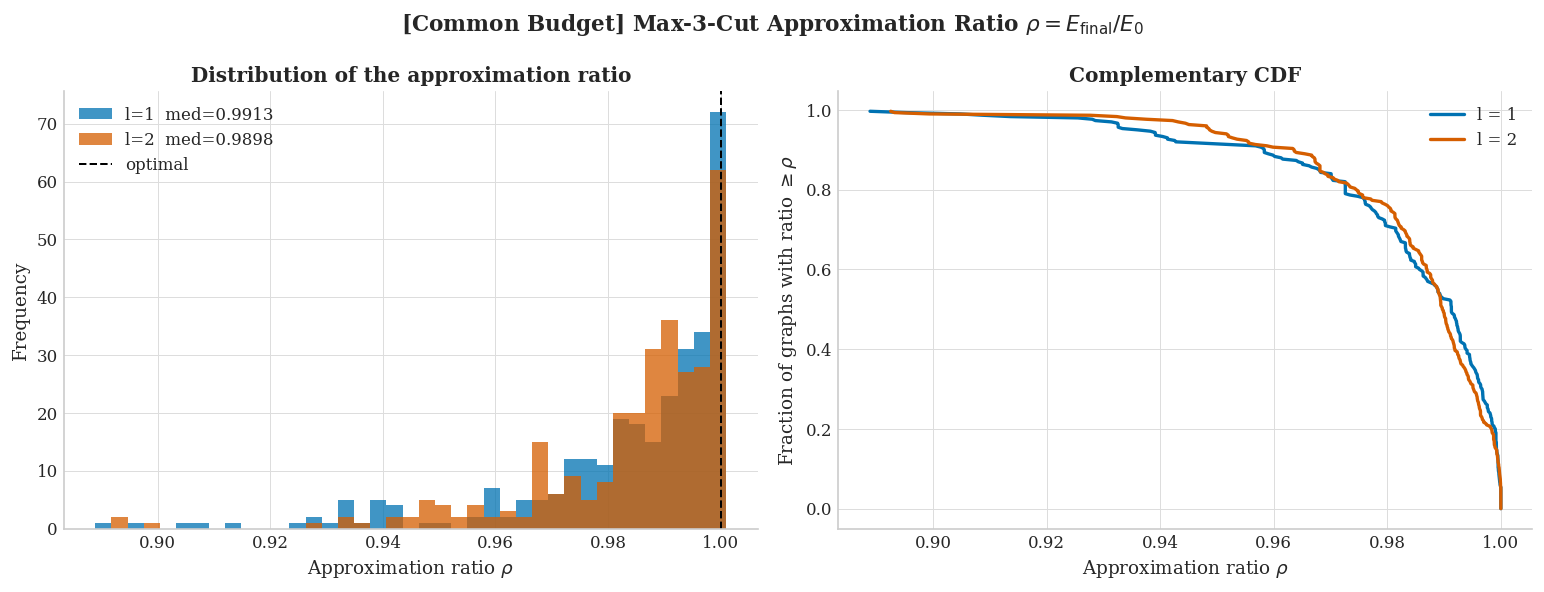

Graphs with ratio >= 0.99:  l=1 → 52.7%  |  l=2 → 49.3%


In [17]:
# [Common budget] Approximation ratio
approx_ratio_l1 = np.array([data_l1[g]["final_energy"] / data_l1[g]["ground_energy"] for g in common_ids])
approx_ratio_l2 = np.array([data_l2[g]["final_energy"] / data_l2[g]["ground_energy"] for g in common_ids])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
bins = np.linspace(min(approx_ratio_l1.min(), approx_ratio_l2.min()), 1.001, 40)
ax.hist(approx_ratio_l1, bins=bins, alpha=0.75, color=C1,
        label=f"l=1  med={np.median(approx_ratio_l1):.4f}")
ax.hist(approx_ratio_l2, bins=bins, alpha=0.75, color=C2,
        label=f"l=2  med={np.median(approx_ratio_l2):.4f}")
ax.axvline(1.0, color="black", linestyle="--", linewidth=1.2, label="optimal")
ax.set_xlabel(r"Approximation ratio $\rho$"); ax.set_ylabel("Frequency")
ax.set_title("Distribution of the approximation ratio"); ax.legend()

ax = axes[1]
for ratio, label, color in [(approx_ratio_l1, "l = 1", C1), (approx_ratio_l2, "l = 2", C2)]:
    sorted_r = np.sort(ratio)
    ax.plot(sorted_r, 1 - np.arange(1, len(sorted_r)+1)/len(sorted_r), color=color, linewidth=2, label=label)
ax.set_xlabel(r"Approximation ratio $\rho$")
ax.set_ylabel(r"Fraction of graphs with ratio $\geq \rho$")
ax.set_title("Complementary CDF"); ax.legend()

plt.suptitle(r"[Common Budget] Max-3-Cut Approximation Ratio $\rho = E_{\mathrm{final}} / E_0$",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"Graphs with ratio >= 0.99:  l=1 → {np.mean(approx_ratio_l1 >= 0.99)*100:.1f}%  "
      f"|  l=2 → {np.mean(approx_ratio_l2 >= 0.99)*100:.1f}%")


**Analysis:** With the same iteration budget, the advantage of `l=2` collapses: only 49.3% of its graphs reach a ratio $\geq 0.99$, practically the same as the 52.7% of `l=1`. Compared with the normal case (94.7% vs 55%), this demonstrates that **the superiority of `l=2` is purely a consequence of using more iterations**, not of higher per-iteration quality.

### 6. Marginal improvement per iteration — Common budget

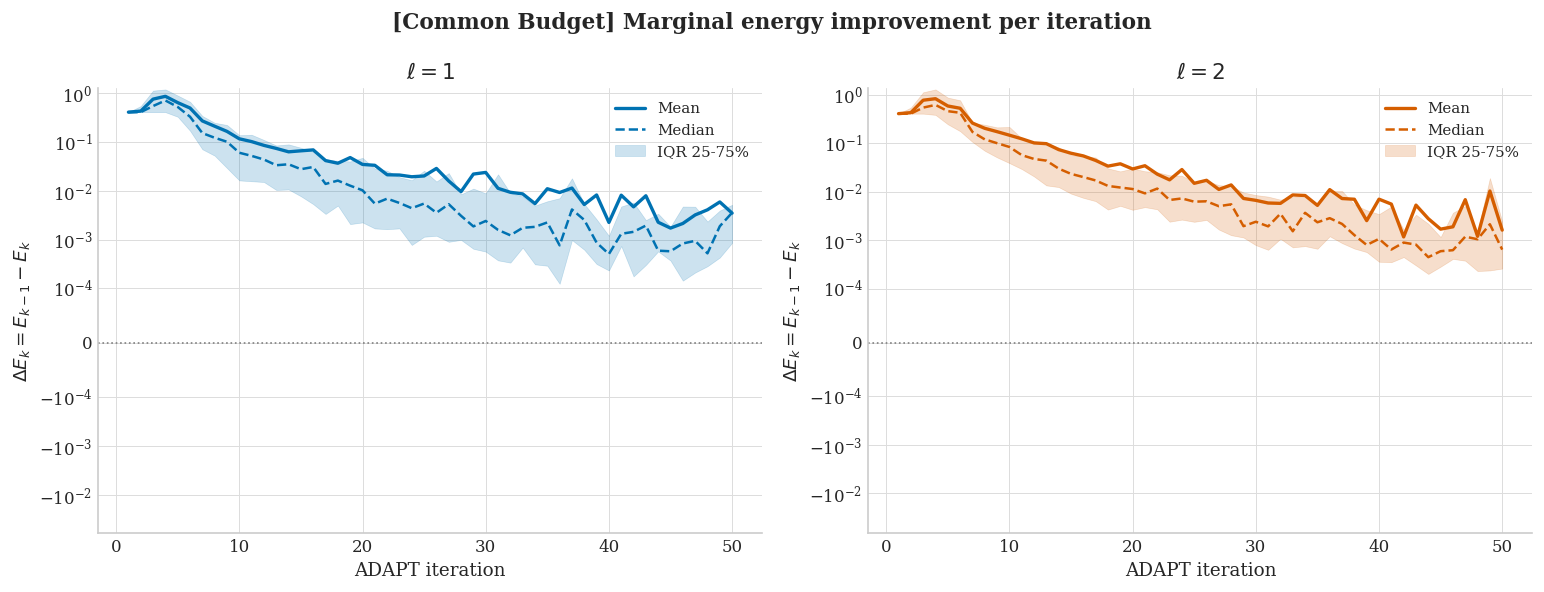

In [18]:
# [Common budget] Marginal improvement per iteration (top panel only)
def compute_marginal_stats_cb(data_dict, r_common_dict):
    all_deltas = []
    max_iters  = max(r_common_dict.values())
    for g, item in data_dict.items():
        r_cut = r_common_dict[g]
        trace  = np.array(item['energy_trace'], dtype=float)[:-1]
        trace  = trace[:r_cut + 1]   # truncate to the common budget
        deltas = np.diff(-trace)
        all_deltas.append(deltas)
    padded = np.full((len(all_deltas), max_iters), np.nan)
    for i, d in enumerate(all_deltas):
        padded[i, :len(d)] = d
    n_active = np.sum(~np.isnan(padded), axis=0)
    return {
        'mean'        : np.nanmean(padded, axis=0),
        'median'      : np.nanmedian(padded, axis=0),
        'q25'         : np.nanpercentile(padded, 25, axis=0),
        'q75'         : np.nanpercentile(padded, 75, axis=0),
        'n_active'    : n_active,
        'frac_active' : n_active / len(all_deltas),
    }

r_common = {g: min(data_l1[g]['iterations'], data_l2[g]['iterations']) for g in common_ids}
marg_l1_cb = compute_marginal_stats_cb(data_l1, r_common)
marg_l2_cb = compute_marginal_stats_cb(data_l2, r_common)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for col, (marg, label, color) in enumerate([
    (marg_l1_cb, '$\ell = 1$', C1),
    (marg_l2_cb, '$\ell = 2$', C2),
]):
    ax = axes[col]
    x = np.arange(1, len(marg['mean']) + 1)

    ax.plot(x, marg['mean'],   color=color, linewidth=2,   label='Mean')
    ax.plot(x, marg['median'], color=color, linewidth=1.5,
            linestyle='--', label='Median')
    ax.fill_between(x, marg['q25'], marg['q75'],
                    color=color, alpha=0.20, label='IQR 25-75%')
    ax.axhline(0, color='gray', linestyle=':', linewidth=1)
    ax.set_ylabel(r'$\Delta E_k = E_{k-1} - E_k$')
    ax.set_yscale('symlog', linthresh=1e-4)
    ax.set_title(label, fontsize=13)
    ax.legend(fontsize=9)
    ax.set_xlabel('ADAPT iteration')

fig.suptitle('[Common Budget] Marginal energy improvement per iteration',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Analysis:** With a common budget, the marginal improvement curves of `l=1` and `l=2` are nearly identical. This confirms that per iteration, both pools produce equivalent energy improvements. The difference seen in the normal case is entirely due to the larger number of iterations performed by `l=2`.

### 7. Does `l=2` use the $O_3$ operators? — Common budget

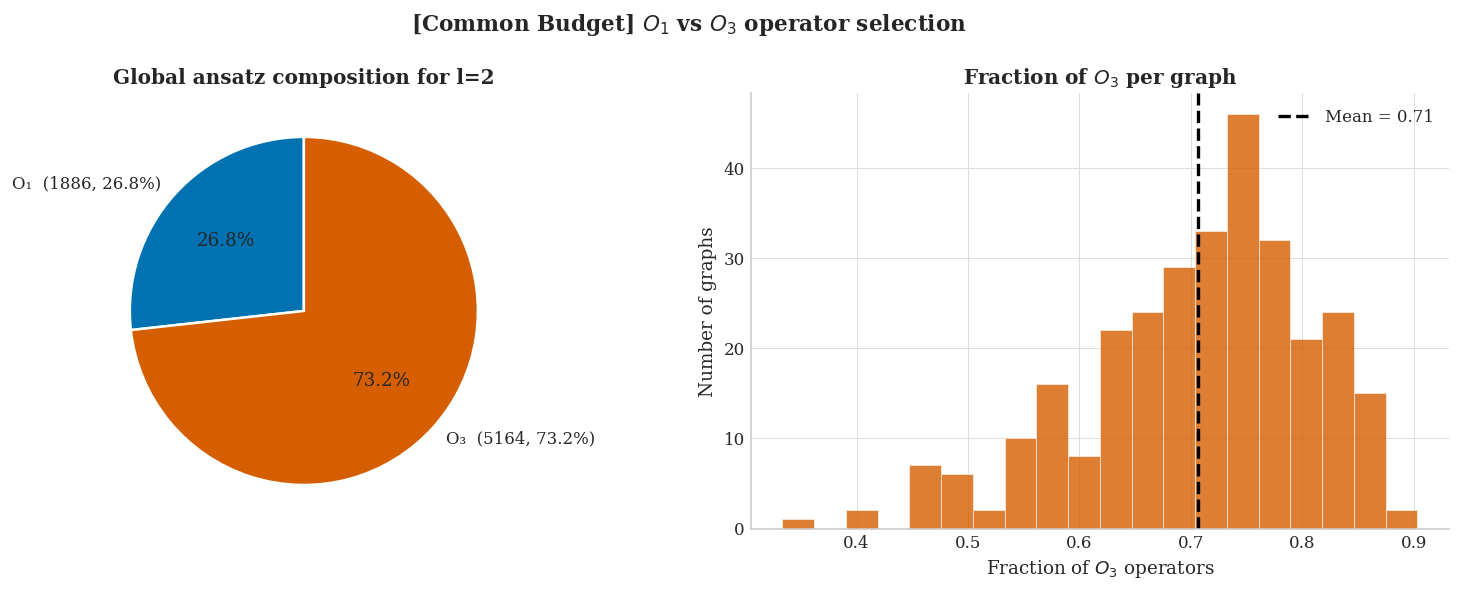

O1: 1886 (26.8%)  |  O3: 5164 (73.2%)


In [19]:
# [Common budget] Does l=2 use the O3 operators?
from collections import Counter
count_o1, count_o3 = 0, 0
per_graph_frac_o3 = []

for gid in common_ids:
    pool_l1_set = set(data_l1[gid].get("pool_labels", []))
    selected    = data_l2[gid].get("ansatz_op_labels", [])
    n_o1 = sum(1 for lbl in selected if lbl in pool_l1_set)
    n_o3 = len(selected) - n_o1
    count_o1 += n_o1; count_o3 += n_o3
    if len(selected) > 0:
        per_graph_frac_o3.append(n_o3 / len(selected))

per_graph_frac_o3 = np.array(per_graph_frac_o3)
total = count_o1 + count_o3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].pie([count_o1, count_o3],
            labels=[f"O₁  ({count_o1}, {100*count_o1/total:.1f}%)",
                    f"O₃  ({count_o3}, {100*count_o3/total:.1f}%)"],
            colors=[C1, C2], autopct="%1.1f%%", startangle=90,
            wedgeprops=dict(edgecolor="white", linewidth=1.5))
axes[0].set_title("Global ansatz composition for l=2")

axes[1].hist(per_graph_frac_o3, bins=20, color=C2, alpha=0.8, edgecolor="white")
axes[1].axvline(np.mean(per_graph_frac_o3), color="black", linestyle="--",
                label=f"Mean = {np.mean(per_graph_frac_o3):.2f}")
axes[1].set_xlabel("Fraction of $O_3$ operators"); axes[1].set_ylabel("Number of graphs")
axes[1].set_title("Fraction of $O_3$ per graph"); axes[1].legend()

plt.suptitle("[Common Budget] $O_1$ vs $O_3$ operator selection", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"O1: {count_o1} ({100*count_o1/total:.1f}%)  |  O3: {count_o3} ({100*count_o3/total:.1f}%)")


**Analysis:** With a common budget, the proportion of $O_3$ drops slightly from 79.5% to 73.2%, but it is still dominant. This indicates that even in the early iterations (those shared with `l=1`), `l=2` already prefers $O_3$ operators. The preference for $O_3$ is not a late-stage phenomenon but appears from the very start of the algorithm.

### 8. Distribution of the optimized parameters $\theta$ — Common budget

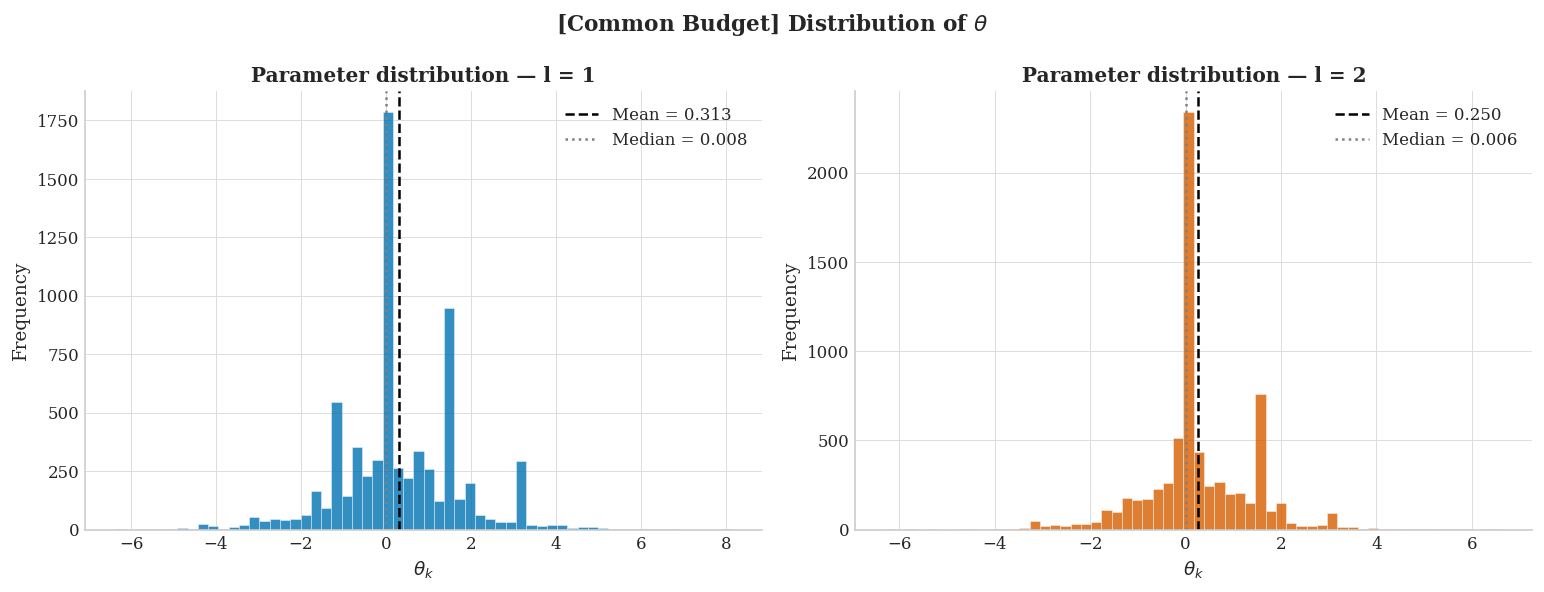

In [20]:
# [Common budget] Distribution of the final theta parameters
all_params_l1, all_params_l2 = [], []
for item in data_l1.values():
    all_params_l1.extend(item.get("params", []))
for item in data_l2.values():
    all_params_l2.extend(item.get("params", []))

all_params_l1 = np.array(all_params_l1)
all_params_l2 = np.array(all_params_l2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, params, label, color in [
    (axes[0], all_params_l1, "l = 1", C1),
    (axes[1], all_params_l2, "l = 2", C2),
]:
    ax.hist(params, bins=60, color=color, alpha=0.8, edgecolor="white", linewidth=0.3)
    ax.axvline(np.mean(params),   color="black", linestyle="--", linewidth=1.5,
               label=f"Mean = {np.mean(params):.3f}")
    ax.axvline(np.median(params), color="gray",  linestyle=":",  linewidth=1.5,
               label=f"Median = {np.median(params):.3f}")
    ax.set_xlabel(r"$\theta_k$"); ax.set_ylabel("Frequency")
    ax.set_title(f"Parameter distribution — {label}"); ax.legend()

plt.suptitle(r"[Common Budget] Distribution of $\theta$", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


**Analysis:** With a common budget, the parameter distributions of both pools resemble each other more than in the normal case, but `l=2` is still more concentrated around zero. This confirms that the difference observed in the normal case is not only a consequence of using more iterations: the $O_3$ operators parametrize the ansatz in a structurally different way, requiring smaller angles even with the same number of steps. The peak at $\theta \approx 0$ remains the dominant feature in both cases, and its interpretation is the same as in the normal case: **accumulated fine corrections**, not redundant operators.

### 9. Expressivity vs. per-step efficiency — Common budget

This section directly quantifies the distinction between **expressivity** (access to better minima) and **per-step efficiency** (energy reduction per selected operator), which is the central argument of the discussion chapter.

The metric used is the **mean marginal improvement per iteration**, defined as:

$$\text{eff} = \frac{1}{r}\sum_{k=1}^{r}|E_k - E_{k-1}| = \frac{E_0 - E_{\text{final}}}{r}$$

where $E_k$ is the energy after adding the $k$-th operator to the ansatz and re-optimizing all parameters, and $r$ is the total number of iterations. The second equality holds because the energy is monotonically decreasing (telescoping sum), so the metric is simply equivalent to the **average slope of the convergence curve**: how many units of energy the algorithm reduces per operator added to the ansatz.

Under the **common budget** ($r = r_{\text{common}}$, the same for both pools on each graph), the point $(x, y)$ of each instance is:

$$x = \frac{E_0 - E_{\text{final}}^{(\ell=1)}}{r_{\text{common}}}, \qquad y = \frac{E_0 - E_{\text{final}}^{(\ell=2)}}{r_{\text{common}}}$$

If both pools are equally efficient per step, the points should cluster along the diagonal $y = x$.

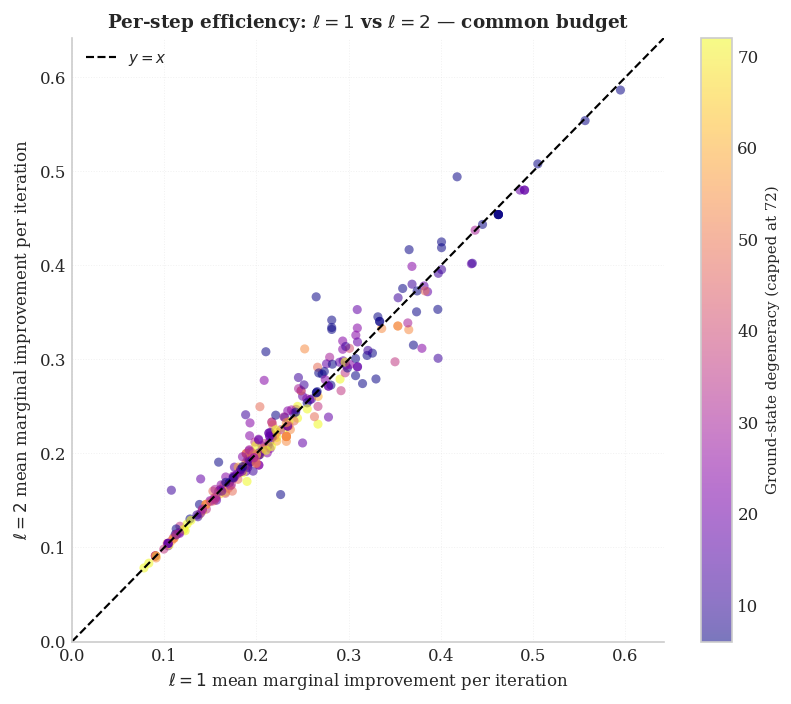

Ratio eff_l2/eff_l1  —  median: 0.996  |  mean: 1.007
Fraction of graphs with eff_l2 > eff_l1: 43.3%


In [21]:
# Per-step efficiency scatter — common budget
from pathlib import Path
import json as _json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors


def _load(path):
    with open(path, "r", encoding="utf-8") as f:
        raw = _json.load(f)
    return {int(item["grafo_id"]): item for item in raw if "error" not in item}

def mean_marginal(trace):
    diffs = np.abs(np.diff(trace))
    return float(np.mean(diffs)) if len(diffs) > 0 else 0.0

d1 = _load("results/json/resultados_completos_n6_l1_common_budget.json")
d2 = _load("results/json/resultados_completos_n6_l2_common_budget.json")
cids = sorted(set(d1) & set(d2))

eff1 = np.array([mean_marginal(d1[g]["energy_trace"]) for g in cids])
eff2 = np.array([mean_marginal(d2[g]["energy_trace"]) for g in cids])
deg  = np.array([d1[g]["ground_degeneracy"] for g in cids])

norm = mcolors.Normalize(vmin=6, vmax=72)
cmap = plt.cm.plasma

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(eff1, eff2, c=np.clip(deg, 6, 72), cmap=cmap, norm=norm,
                alpha=0.55, s=30, edgecolors="none")
cb = plt.colorbar(sc, ax=ax)
cb.set_label("Ground-state degeneracy (capped at 72)", fontsize=9)

lim = max(eff1.max(), eff2.max()) * 1.08
ax.plot([0, lim], [0, lim], "k--", lw=1.3, label="$y = x$")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("$\\ell=1$ mean marginal improvement per iteration", fontsize=10)
ax.set_ylabel("$\\ell=2$ mean marginal improvement per iteration", fontsize=10)
ax.set_title("Per-step efficiency: $\\ell=1$ vs $\\ell=2$ — common budget", fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, ls=":", alpha=0.4)
plt.tight_layout()
plt.show()

ratio = eff2 / np.where(eff1 > 1e-10, eff1, np.nan)
print(f"Ratio eff_l2/eff_l1  —  median: {np.nanmedian(ratio):.3f}  |  mean: {np.nanmean(ratio):.3f}")
print(f"Fraction of graphs with eff_l2 > eff_l1: {(eff2 > eff1).mean()*100:.1f}%")


**Analysis.**

Under the common budget, the points cluster around the diagonal $y=x$: the mean marginal improvement per iteration is statistically equivalent for $\ell=1$ and $\ell=2$, graph by graph. The median ratio $\text{eff}_{\ell=2}/\text{eff}_{\ell=1}$ (printed above) quantitatively confirms this equivalence.

The color encodes the ground-state degeneracy: easy graphs (high degeneracy, yellow) show high efficiencies on both axes; hard ones (low degeneracy, purple) cluster near the origin. Across all difficulty ranges, the ratio between efficiencies stays close to 1, confirming that the per-step equivalence does not depend on the graph's structure.